
# AI-Powered Business Intelligence & Analytics

## Exploratory Data Analysis (EDA)

### Project Overview
This notebook explores the Brazilian E-Commerce Public Dataset by Olist.

The objective is to understand sales performance, product trends, customer behavior, and payment patterns to identify actionable business insights.

### Analysis Objectives
1. Understand the structure of the datasets.
2. Inspect missing values and duplicate records.
3. Analyze revenue and product performance.
4. Explore customer purchasing behavior.
5. Identify trends and unusual transactions.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Processed data directory
DATA_PATH = PROJECT_ROOT / "data" / "processed"

print("Project directory:", PROJECT_ROOT)
print("Data directory:", DATA_PATH)


Project directory: c:\Users\1234\OneDrive\Desktop\ai-powered-business-intelligence
Data directory: c:\Users\1234\OneDrive\Desktop\ai-powered-business-intelligence\data\processed


In [2]:

customers = pd.read_csv(DATA_PATH / "customers_cleaned.csv")
orders = pd.read_csv(DATA_PATH / "orders_cleaned.csv")
order_items = pd.read_csv(DATA_PATH / "order_items_cleaned.csv")
payments = pd.read_csv(DATA_PATH / "payments_cleaned.csv")
reviews = pd.read_csv(DATA_PATH / "reviews_cleaned.csv")
products = pd.read_csv(DATA_PATH / "products_cleaned.csv")
sellers = pd.read_csv(DATA_PATH / "sellers_cleaned.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!



## 1. Dataset Overview

This section examines the structure of the seven datasets used in the analysis, including their dimensions, column names, data types, and sample records.


In [3]:

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])



Customers
----------------------------------------
Rows: 99441
Columns: 5

Orders
----------------------------------------
Rows: 99441
Columns: 9

Order Items
----------------------------------------
Rows: 112650
Columns: 8

Payments
----------------------------------------
Rows: 103886
Columns: 6

Reviews
----------------------------------------
Rows: 99224
Columns: 7

Products
----------------------------------------
Rows: 32951
Columns: 11

Sellers
----------------------------------------
Rows: 3095
Columns: 4


In [4]:

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("-" * 50)
    df.info()



CUSTOMERS
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

ORDERS
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   

In [5]:

display(customers.head())
display(orders.head())
display(order_items.head())


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_missing_flag
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,invalid_price
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,False
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,False
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,False
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,False



## 2. Data Quality Analysis

This section examines missing values and duplicate records across the seven datasets.

The objective is to understand data-quality issues and determine whether missing values require correction, retention, or further investigation.


In [6]:

missing_summary = []

for name, df in datasets.items():
    for column in df.columns:
        missing_count = df[column].isnull().sum()
        missing_percentage = (missing_count / len(df)) * 100

        if missing_count > 0:
            missing_summary.append({
                "Dataset": name,
                "Column": column,
                "Missing Values": missing_count,
                "Missing Percentage": round(missing_percentage, 2)
            })

missing_df = pd.DataFrame(missing_summary)

display(
    missing_df.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)


,Dataset,Column,Missing Values,Missing Percentage
3,Reviews,review_comment_title,87656,88.34
4,Reviews,review_comment_message,58247,58.70
2,Orders,order_delivered_customer_date,2965,2.98
5,Products,product_name_lenght,610,1.85
6,Products,product_description_lenght,610,1.85
7,Products,product_photos_qty,610,1.85
1,Orders,order_delivered_carrier_date,1783,1.79
0,Orders,order_approved_at,160,0.16
8,Products,product_weight_g,2,0.01
9,Products,product_length_cm,2,0.01


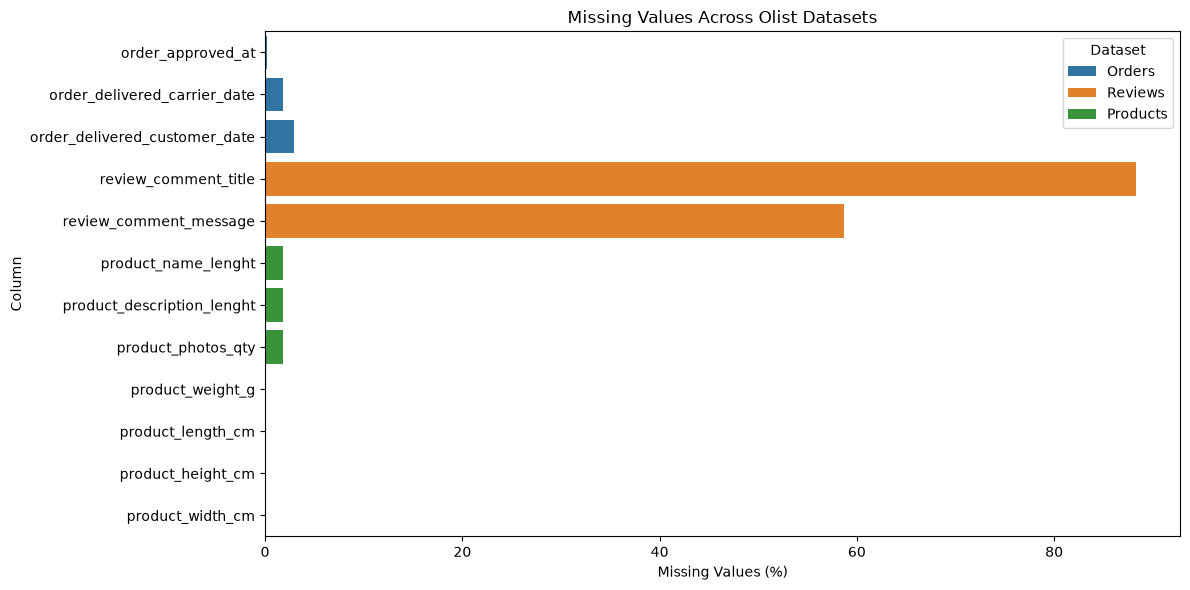

In [7]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_df,
    x="Missing Percentage",
    y="Column",
    hue="Dataset"
)

plt.title("Missing Values Across Olist Datasets")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


In [8]:

duplicate_summary = []

for name, df in datasets.items():
    duplicate_summary.append({
        "Dataset": name,
        "Duplicate Rows": df.duplicated().sum()
    })

duplicate_df = pd.DataFrame(duplicate_summary)

display(duplicate_df)


,Dataset,Duplicate Rows
0,Customers,0
1,Orders,0
2,Order Items,0
3,Payments,0
4,Reviews,0
5,Products,0
6,Sellers,0



### Data Quality Findings

- Orders contain missing delivery timestamps, primarily for orders that were not delivered.
- Review comments contain substantial missing values because customers do not always leave written feedback.
- Product records contain some missing category and physical measurement information.
- Review scores are available even when written comments are missing.
- Exact duplicate rows were not identified in the seven datasets.

Missing values were handled selectively during preprocessing. Optional review comments and unavailable physical measurements were retained rather than filled with arbitrary values. Missing product categories were labeled as "unknown".



## 3. Revenue and Product Performance Analysis

This section analyzes sales revenue, product category performance, and monthly revenue trends.

Product revenue is calculated using the price of items in delivered orders. Freight charges are excluded.


In [9]:

# Merge orders with order items
sales_df = orders.merge(
    order_items,
    on="order_id",
    how="inner"
)

# Keep delivered orders only
sales_df = sales_df[
    sales_df["order_status"] == "delivered"
].copy()

# Convert purchase timestamp
sales_df["order_purchase_timestamp"] = pd.to_datetime(
    sales_df["order_purchase_timestamp"],
    errors="coerce"
)

# Calculate monthly period
sales_df["month"] = (
    sales_df["order_purchase_timestamp"].dt.to_period("M")
)

print("Sales data prepared successfully!")
print("Total delivered order items:", len(sales_df))
print("Total product revenue: R$", round(sales_df["price"].sum(), 2))


Sales data prepared successfully!
Total delivered order items: 110197
Total product revenue: R$ 13221498.11


In [10]:

# Merge product categories
category_sales = sales_df.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Calculate revenue by category
category_revenue = (
    category_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

category_revenue.columns = [
    "Product Category",
    "Total Revenue"
]

display(category_revenue)


,Product Category,Total Revenue
0,beleza_saude,1233131.72
1,relogios_presentes,1166176.98
2,cama_mesa_banho,1023434.76
3,esporte_lazer,954852.55
4,informatica_acessorios,888724.61
5,moveis_decoracao,711927.69
6,utilidades_domesticas,615628.69
7,cool_stuff,610204.10
8,automotivo,578966.65
9,brinquedos,471286.48


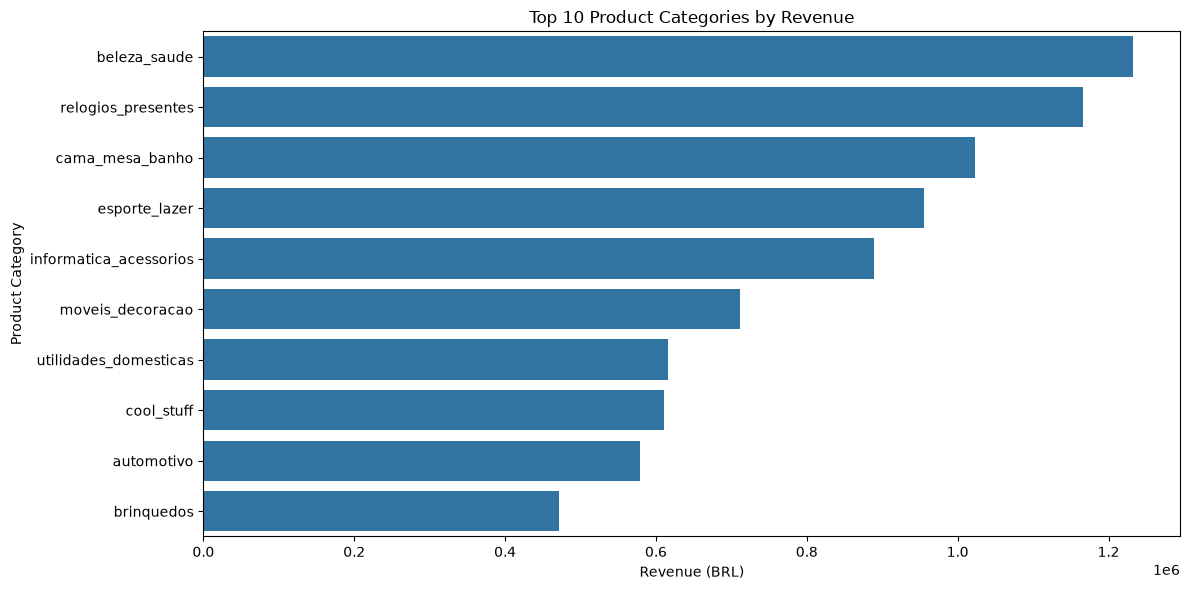

In [11]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue,
    x="Total Revenue",
    y="Product Category"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [12]:

monthly_revenue = (
    sales_df.groupby("month")["price"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = (
    monthly_revenue["month"].astype(str)
)

display(monthly_revenue.head())


,month,price
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40


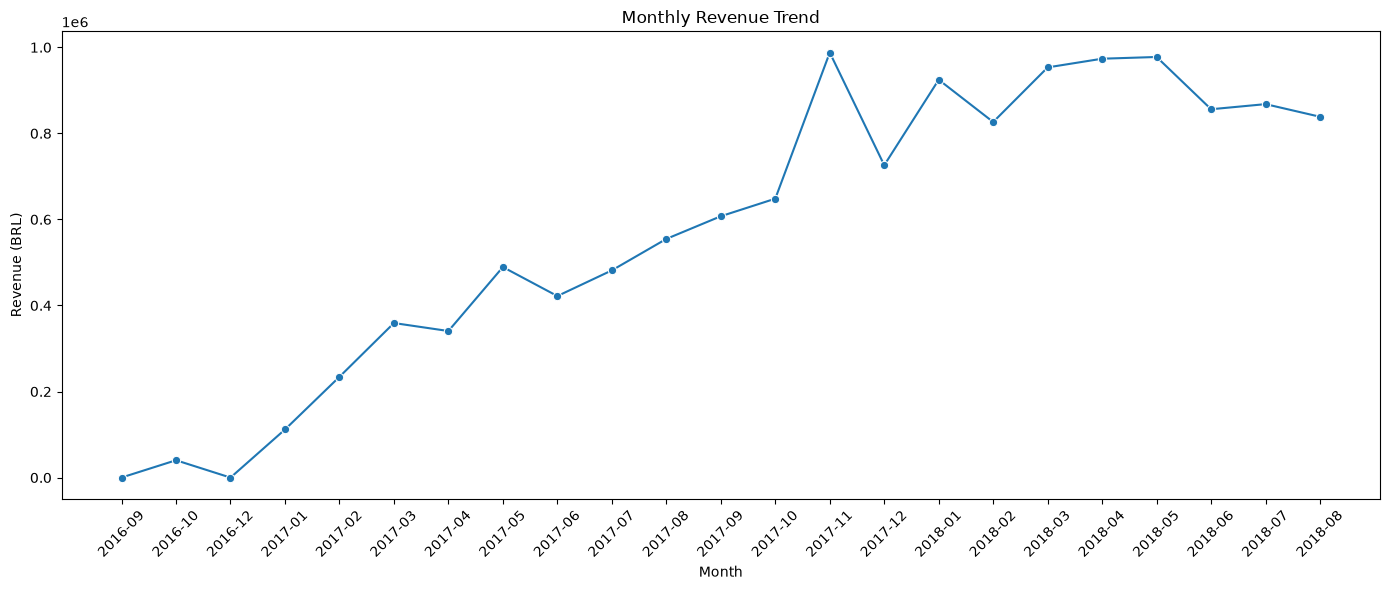

In [13]:

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="price",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 4. Customer Behavior Analysis

This section explores customer purchasing patterns, repeat purchase behavior, and customer revenue segmentation.

The customer_unique_id field is used to identify individual customers across orders, rather than customer_id, which identifies a customer record associated with an order.


In [14]:

# Merge customer, order, and item data
customer_sales = (
    customers[["customer_id", "customer_unique_id"]]
    .merge(
        orders[["order_id", "customer_id", "order_status"]],
        on="customer_id",
        how="inner"
    )
    .merge(
        order_items[["order_id", "price"]],
        on="order_id",
        how="inner"
    )
)

# Keep delivered orders
customer_sales = customer_sales[
    customer_sales["order_status"] == "delivered"
].copy()

# Aggregate at unique customer level
customer_metrics = (
    customer_sales.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("price", "sum")
    )
    .reset_index()
)

display(customer_metrics.head())


,customer_unique_id,total_orders,total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90
2,0000f46a3911fa3c0805444483337064,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,180.00


In [15]:

total_customers = len(customer_metrics)

repeat_customers = (
    customer_metrics["total_orders"] >= 2
).sum()

one_time_customers = (
    customer_metrics["total_orders"] == 1
).sum()

repeat_purchase_rate = (
    repeat_customers / total_customers
) * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)
print("Repeat purchase rate:", round(repeat_purchase_rate, 2), "%")


Total customers: 93358
Repeat customers: 2801
One-time customers: 90557
Repeat purchase rate: 3.0 %


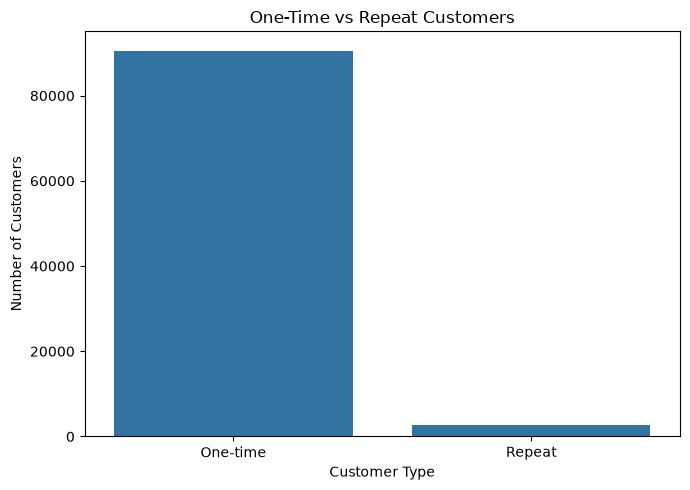

In [16]:

purchase_counts = pd.DataFrame({
    "Customer Type": ["One-time", "Repeat"],
    "Customers": [one_time_customers, repeat_customers]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=purchase_counts,
    x="Customer Type",
    y="Customers"
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [17]:

top_customers = (
    customer_metrics
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

display(top_customers)


,customer_unique_id,total_orders,total_revenue
3724,0a0a92112bd4c708ca5fde585afaa872,1,13440.0
79636,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0
80463,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0
25436,459bef486812aa25204be022145caa62,1,6729.0
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0
23411,4007669dec559734d6f53e029e360987,1,5934.6
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0
26640,48e1ac109decbb87765a3eade6854098,1,4590.0
59163,a229eba70ec1c2abef51f04987deb7a5,1,4400.0


In [18]:

customer_metrics["revenue_decile"] = (
    customer_metrics["total_revenue"]
    .rank(method="first", ascending=False)
    .pipe(lambda x: pd.qcut(
        x,
        q=10,
        labels=False
    ))
    + 1
)

customer_metrics["customer_segment"] = np.select(
    [
        customer_metrics["revenue_decile"].isin([1, 2]),
        customer_metrics["revenue_decile"].isin([3, 4, 5])
    ],
    [
        "High Value",
        "Mid Value"
    ],
    default="Low Value"
)

segment_summary = (
    customer_metrics.groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        segment_revenue=("total_revenue", "sum"),
        avg_customer_revenue=("total_revenue", "mean")
    )
    .reset_index()
)

display(segment_summary)


,customer_segment,total_customers,segment_revenue,avg_customer_revenue
0,High Value,18672,7486237.06,400.933861
1,Low Value,46679,2206263.55,47.264585
2,Mid Value,28007,3528997.50,126.004124


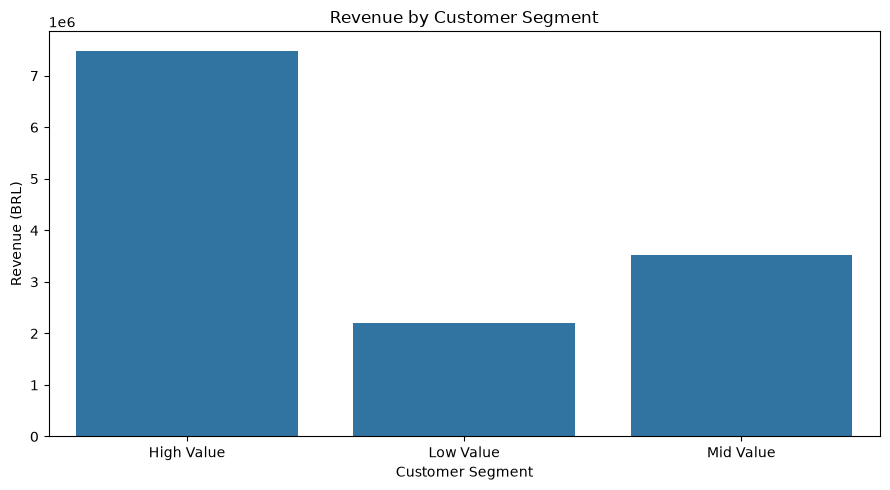

In [19]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="segment_revenue"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()



## 5. Payment Behavior Analysis

This section examines customer payment preferences and compares the number of orders and total payment value across different payment methods.


In [20]:

# Keep payments associated with delivered orders
payment_analysis = payments.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="inner"
)

payment_analysis = payment_analysis[
    payment_analysis["order_status"] == "delivered"
].copy()

payment_summary = (
    payment_analysis.groupby("payment_type")
    .agg(
        total_orders=("order_id", "nunique"),
        total_payment=("payment_value", "sum"),
        average_payment=("payment_value", "mean")
    )
    .reset_index()
    .sort_values("total_payment", ascending=False)
)

display(payment_summary.round(2))


,payment_type,total_orders,total_payment,average_payment
1,credit_card,74304,12101094.88,162.24
0,boleto,19191,2769932.58,144.33
3,voucher,3679,343013.19,62.45
2,debit_card,1485,208421.12,140.26


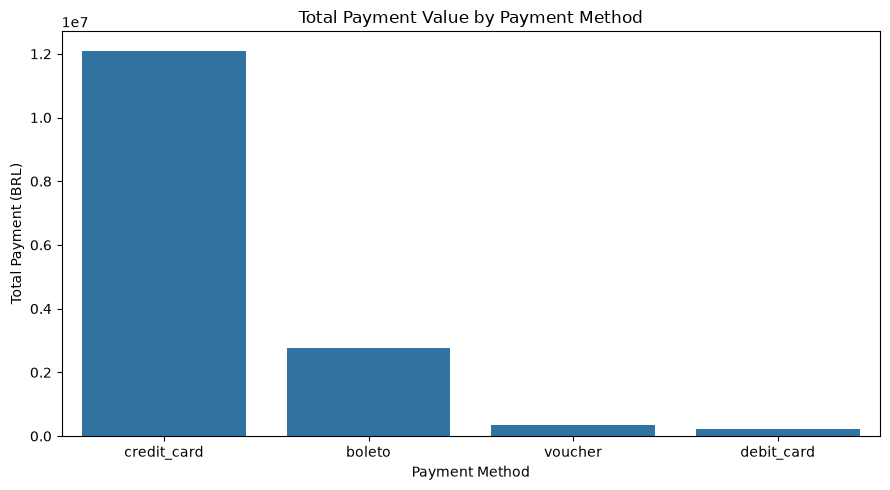

In [21]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_summary,
    x="payment_type",
    y="total_payment"
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment (BRL)")
plt.tight_layout()
plt.show()



## 6. Customer Satisfaction Analysis

This section examines customer review scores to understand satisfaction levels and identify opportunities to improve the customer experience.


In [22]:

review_summary = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_summary.columns = ["Review Score", "Number of Reviews"]

display(review_summary)
print(
    "Average review score:",
    round(reviews["review_score"].mean(), 2)
)


,Review Score,Number of Reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


Average review score: 4.09


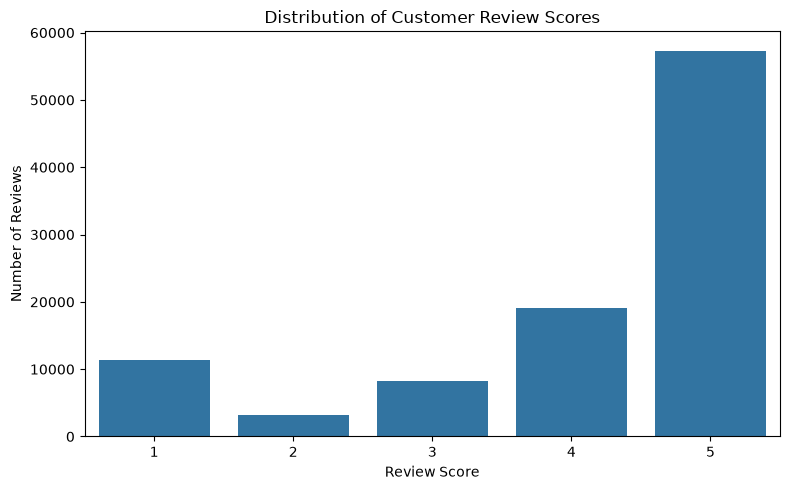

In [23]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()



## 7. Key Business Insights and Recommendations

### 1. Product Performance
Health & Beauty, Watches & Gifts, and Bed Bath & Table are among the highest-revenue product categories.

**Recommendation:** Prioritize inventory planning and marketing campaigns for strong-performing categories.

### 2. Revenue Trends
Monthly revenue analysis shows changes in marketplace performance, including periods of declining revenue.

**Recommendation:** Monitor month-over-month revenue and investigate seasonal or category-specific changes.

### 3. Customer Retention
Only approximately 3% of customers make repeat purchases.

**Recommendation:** Introduce customer retention campaigns, personalized recommendations, and loyalty incentives.

### 4. Customer Segmentation
The high-value customer segment contributes a disproportionately large share of revenue.

**Recommendation:** Develop targeted retention strategies for high-value customers.

### 5. Payment Preferences
Credit cards are the dominant payment method, followed by boleto.

**Recommendation:** Maintain a smooth credit-card checkout experience and investigate opportunities to improve adoption of other payment methods.

### 6. Customer Satisfaction
Review scores provide an opportunity to identify customer experience issues.

**Recommendation:** Investigate low-rated reviews and identify recurring delivery, product, or service problems.

### 7. Revenue Anomalies
Several orders have unusually high revenue compared with the average order.

**Recommendation:** Monitor unusually high-value orders and investigate them before treating them as data errors.
